# Day 3 lab: Applied Lab 3 — Text mining application

<p class="lead">
Turn ten free-text customer reviews of a tablet computer into numbers: split the text into words, remove the words that carry no meaning, find the product features customers mention most, score each review's sentiment with VADER, and recommend one change to the engineering teams.
</p>

*Adapted from the DATA 300 syllabus, Applied Lab 3 (Text Mining Application), for local Jupyter without internet access.*

| | |
|---|---|
| **Graded** | Yes: **3%** of the course grade |
| **Outcomes** | CLO 1, 2 and 3 |
| **Tool** | JupyterLab (Anaconda), with NLTK and WordCloud |
| **You submit** | One PDF, `YourLastName_DATA300_AppliedLab3.pdf`, in the **Applied Lab 3** drop-box on **GAP (Moodle)** |
| **Deadline** | Thursday 12 November, 23:59 China Standard Time, unless your facilitator says otherwise (see the [schedule](schedule.md)) |

---

## The business scenario

You are an analytics consultant for **OmniTech Solutions**. Its customer-service team has collected written reviews of the company's flagship tablet, the **OmniPad Pro**. Reading thousands of reviews by hand is slow and does not scale, so the team wants an automated method, tested first on a small batch of ten reviews.

Your tasks:

1. **Key terms:** split the reviews into words and find the terms customers use most, to see which topics come up most often.
2. **Sentiment:** score every review with a lexicon-based sentiment model on a scale from −1.0 (very negative) to +1.0 (very positive).
3. **Recommendation:** turn the counts and scores into one concrete suggestion for the product engineering teams.

This combines **descriptive** analytics (what customers say) with text mining, a way to find patterns in **unstructured** data.

### Before you start

1. Keep this notebook in the course folder, next to the `data` folder.
2. Save your own copy: **File → Save Notebook As…** and type `YourLastName_Data300_AppliedLab3.ipynb` (with your real last name). Work in that copy.
3. The code below works as given. Run each cell in order with **Shift + Enter**, read the output, and answer the questions in Part 4. You may add cells of your own to check an answer.

---

## Part 1: Set up NLTK and load the reviews

The first cell points NLTK, the Natural Language Toolkit, to the word lists bundled in the `data` folder (the tokenizer, the English stopword list and the VADER sentiment lexicon), so nothing is downloaded from the internet.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

The next cell loads the other libraries and the ten reviews. One row is one customer review.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud

pd.set_option("display.max_colwidth", 110)

data = {
    "Review_ID": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Review_Text": [
        "Absolutely love the new OmniPad! The battery life is amazing and the screen is beautiful.",
        "Terrible experience. The screen cracked after one week and customer service was completely useless.",
        "It is an okay tablet. Nothing special, but it gets the job done for basic web browsing.",
        "The battery life is incredibly poor. I have to charge it twice a day. Very disappointed.",
        "Fantastic device! Fast processor, great camera, and very lightweight. Highly recommend.",
        "Overpriced garbage. The software is laggy and it crashes constantly.",
        "A solid upgrade from the previous generation. The stylus integration is perfect for my artwork.",
        "I hate the new update. It ruined the user interface and made everything slower.",
        "Decent value for the price. The battery is fine, but the camera could be better.",
        "Best purchase I've made this year. Beautiful display and amazing battery life!",
    ],
}
df = pd.DataFrame(data)

print("--- Raw customer reviews (first five) ---")
df.head()

--- Raw customer reviews (first five) ---


,Review_ID,Review_Text
0,1,Absolutely love the new OmniPad! The battery life is amazing and the screen is beautiful.
1,2,Terrible experience. The screen cracked after one week and customer service was completely useless.
2,3,"It is an okay tablet. Nothing special, but it gets the job done for basic web browsing."
3,4,The battery life is incredibly poor. I have to charge it twice a day. Very disappointed.
4,5,"Fantastic device! Fast processor, great camera, and very lightweight. Highly recommend."


---

## Part 2: Text preprocessing and key terms

Before counting anything, the text must be prepared:

1. **Combine and lowercase** all reviews, so "Battery" and "battery" count as one word.
2. **Tokenise**: split the text into single words (tokens) with `word_tokenize`.
3. **Filter**: keep only tokens made of letters (this drops punctuation and numbers) and remove **stopwords**. We add three domain words, *omnipad*, *tablet* and *device*, because every review is about the product and they cannot tell one review from another.

Then a **word cloud** draws each remaining word with a size that grows with its frequency, and a frequency count lists the five most common keywords. The fixed `random_state` keeps the word cloud layout the same each time you run it.

Tokens before cleaning: 166 | words kept: 83


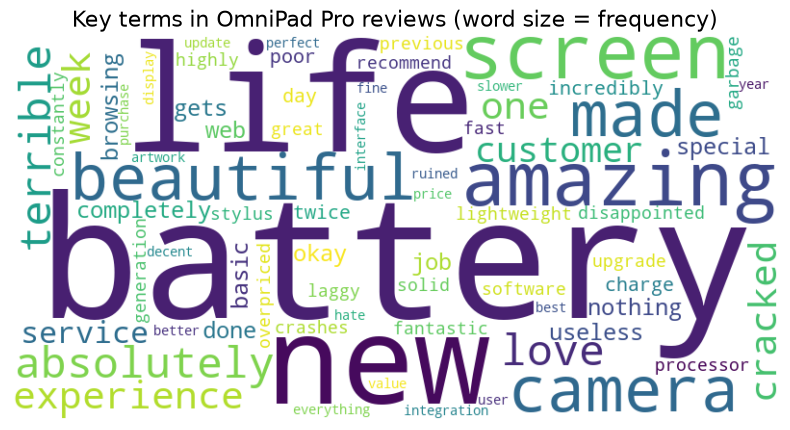

--- Top 5 most frequent keywords ---
Keyword: 'battery' | Frequency count: 4
Keyword: 'life' | Frequency count: 3
Keyword: 'new' | Frequency count: 2
Keyword: 'amazing' | Frequency count: 2
Keyword: 'screen' | Frequency count: 2


In [3]:
# 1. Combine all reviews into one lowercase string
all_text = " ".join(review for review in df["Review_Text"]).lower()

# 2. Stopword list: NLTK's English list plus three domain words with no distinguishing signal
stop_words = set(stopwords.words("english"))
stop_words.update(["omnipad", "tablet", "device"])

# 3. Tokenise, then keep alphabetic tokens that are not stopwords
words = word_tokenize(all_text)
cleaned_words = [word for word in words if word.isalpha() and word not in stop_words]
print("Tokens before cleaning:", len(words), "| words kept:", len(cleaned_words))

# 4. Word cloud of the cleaned words
wordcloud = WordCloud(
    width=800, height=400, background_color="white", colormap="viridis", random_state=42
).generate(" ".join(cleaned_words))

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Key terms in OmniPad Pro reviews (word size = frequency)", fontsize=16)
plt.show()

# 5. The five most frequent keywords
freq_dist = nltk.FreqDist(cleaned_words)
print("--- Top 5 most frequent keywords ---")
for word, frequency in freq_dist.most_common(5):
    print(f"Keyword: '{word}' | Frequency count: {frequency}")

Use the word cloud and the top-five list above for questions 1 and 2.

---

## Part 3: Sentiment analysis with VADER

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) is a **rule-based** sentiment model designed for short, informal texts such as product reviews and social media posts. It looks up each word in a **lexicon** of rated words, adjusts the ratings with rules (for negation such as "not", intensifiers such as "very", capital letters and exclamation marks), and combines them into a **compound score** *S* between −1.0 and +1.0.

We label each review with the usual thresholds:

| Compound score | Label |
|---|---|
| S ≥ 0.05 | Positive |
| −0.05 < S < 0.05 | Neutral |
| S ≤ −0.05 | Negative |

VADER runs on the **original** review text, not on the cleaned words: removing stopwords such as "not" or "very" would change the meaning.

In [4]:
# 1. Create the VADER analyser (it reads the bundled lexicon)
analyzer = SentimentIntensityAnalyzer()

# 2. Compound score for every review
df["Compound_Score"] = df["Review_Text"].apply(lambda text: analyzer.polarity_scores(text)["compound"])


# 3. Turn the score into a label with the thresholds above
def categorize_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


df["Sentiment_Label"] = df["Compound_Score"].apply(categorize_sentiment)

print("--- Sentiment results for each review ---")
df[["Review_ID", "Review_Text", "Compound_Score", "Sentiment_Label"]]

--- Sentiment results for each review ---


,Review_ID,Review_Text,Compound_Score,Sentiment_Label
0,1,Absolutely love the new OmniPad! The battery life is amazing and the screen is beautiful.,0.9258,Positive
1,2,Terrible experience. The screen cracked after one week and customer service was completely useless.,-0.7346,Negative
2,3,"It is an okay tablet. Nothing special, but it gets the job done for basic web browsing.",-0.0462,Neutral
3,4,The battery life is incredibly poor. I have to charge it twice a day. Very disappointed.,-0.7774,Negative
4,5,"Fantastic device! Fast processor, great camera, and very lightweight. Highly recommend.",0.9011,Positive
5,6,Overpriced garbage. The software is laggy and it crashes constantly.,0.0000,Neutral
6,7,A solid upgrade from the previous generation. The stylus integration is perfect for my artwork.,0.6486,Positive
7,8,I hate the new update. It ruined the user interface and made everything slower.,-0.7783,Negative
8,9,"Decent value for the price. The battery is fine, but the camera could be better.",0.7140,Positive
9,10,Best purchase I've made this year. Beautiful display and amazing battery life!,0.9215,Positive


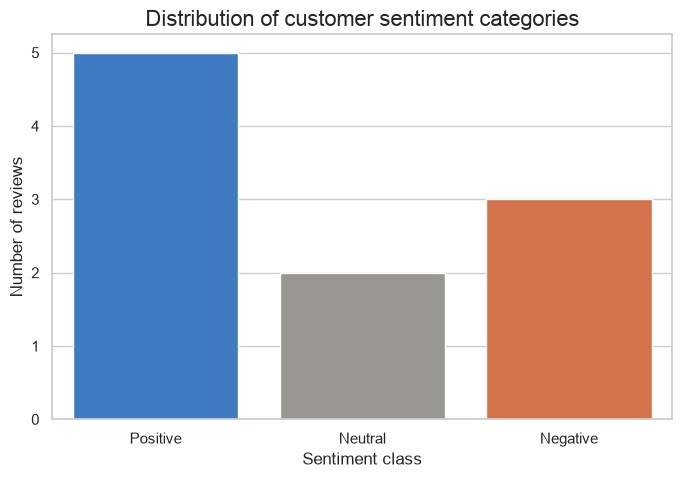

Sentiment_Label
Positive    5
Neutral     2
Negative    3


In [5]:
# 4. How many reviews fall in each sentiment class?
label_order = ["Positive", "Neutral", "Negative"]
colours = {"Positive": "#2a78d6", "Neutral": "#9a9890", "Negative": "#eb6834"}   # colour-blind-safe

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df, x="Sentiment_Label", hue="Sentiment_Label",
    order=label_order, hue_order=label_order, palette=colours, legend=False,
)
plt.title("Distribution of customer sentiment categories", fontsize=16)
plt.xlabel("Sentiment class")
plt.ylabel("Number of reviews")
plt.show()

print(df["Sentiment_Label"].value_counts().reindex(label_order, fill_value=0).to_string())

Use the table and the bar chart above for questions 3, 4 and 5.

---

## Part 4: Questions

Answer **all five questions in complete sentences** in the answer cell below. Base every answer on the outputs in this notebook, and quote the numbers you use.

### Section A: Preprocessing and key terms

| # | Question |
|---|---|
| **1** | In your own words, what is a **stopword** in natural language processing? Why must stopwords be removed **before** you count word frequencies, from the point of view of a data analyst? |
| **2** | Look at the word cloud and the top-five keyword list in Part 2. Which **hardware component or product feature** of the OmniPad Pro do customers mention most often? Give its frequency count. |

### Section B: Reading the sentiment scores

| # | Question |
|---|---|
| **3** | (a) Find **Review 6** (*"Overpriced garbage. The software is laggy and it crashes constantly."*) in the Part 3 table and state its exact `Compound_Score`. (b) Does that score agree with how a person would read the review? Explain why the score came out the way it did. |
| **4** | **Review 3** (*"It is an okay tablet. Nothing special, but it gets the job done for basic web browsing."*) is labelled **Neutral**. Using its compound score and the thresholds (−0.05 < S < 0.05), explain why VADER puts it in that class. |

### Section C: Supporting a business decision

| # | Question |
|---|---|
| **5** | Combine the sentiment distribution chart with the key terms from Part 2. As OmniTech's analytics consultant, give **one actionable recommendation** to the hardware or software engineering team for the next version of the product. Support it with specific numbers or reviews from your outputs, and state one limitation of evidence based on ten reviews. |

> **Writing tips**
>
> Lead with the answer, then the evidence: *"Customers talk about … more than any other feature: it appears … times, in both the most positive and the most negative reviews."* Name the output you used (the table, the chart, the keyword list). For question 3(b), think about which words VADER's lexicon does and does not contain.

> **My answers**
>
> **Name:** *Your name* · **Student ID:** *Your ID*
>
> **1. Stopwords and why they are removed:** *Your answer*
>
> **2. Most discussed feature and its count:** *Your answer*
>
> **3. (a) Compound score of Review 6:** *Your answer*
>
> **3. (b) Does it match a human reading, and why:** *Your answer*
>
> **4. Why Review 3 is Neutral:** *Your answer*
>
> **5. Recommendation, evidence and one limitation:** *Your answer*

---

## Going further (not graded)

A general-purpose lexicon does not know every word customers use about technology. The cell below makes a **second** analyser, adds four product-review words with ratings we chose ourselves (on VADER's scale from about −4 to +4), and scores all reviews again next to the original scores. It also lists the most common **word pairs**, which keep phrases such as "battery life" together.

In [6]:
from collections import Counter

custom = SentimentIntensityAnalyzer()
custom.lexicon.update({"garbage": -3.0, "laggy": -2.0, "crashes": -2.0, "overpriced": -1.5})

comparison = df[["Review_ID", "Compound_Score"]].copy()
comparison["Custom_Score"] = df["Review_Text"].apply(lambda text: custom.polarity_scores(text)["compound"])
comparison["Custom_Label"] = comparison["Custom_Score"].apply(categorize_sentiment)
print("Original and custom-lexicon scores")
print(comparison.to_string(index=False))

pairs = Counter()
for review in df["Review_Text"]:
    tokens = [w for w in word_tokenize(review.lower()) if w.isalpha() and w not in stop_words]
    pairs.update(nltk.bigrams(tokens))
print("\nMost common word pairs:")
for (first, second), count in pairs.most_common(5):
    print(f"  {first} {second}: {count}")

Original and custom-lexicon scores
 Review_ID  Compound_Score  Custom_Score Custom_Label
         1          0.9258        0.9258     Positive
         2         -0.7346       -0.7346     Negative
         3         -0.0462       -0.0462      Neutral
         4         -0.7774       -0.7774     Negative
         5          0.9011        0.9011     Positive
         6          0.0000       -0.9100     Negative
         7          0.6486        0.6486     Positive
         8         -0.7783       -0.7783     Negative
         9          0.7140        0.7140     Positive
        10          0.9215        0.9215     Positive

Most common word pairs:
  battery life: 3
  absolutely love: 1
  love new: 1
  new battery: 1
  life amazing: 1


Which reviews changed class? Who should choose the ratings for new words, and how could a careless choice bias the result? With thousands of reviews, how would you check that the custom lexicon is better than the original?

---

## Part 5: Export and submit

### 1. Export to PDF

1. Choose **Kernel → Restart Kernel and Run All Cells**. Check that the review table, the word cloud, the top-five list, the sentiment table and the bar chart all appear, and that your answers are in the answer cell.
2. Choose **File → Print** (or Ctrl + P / Cmd + P).
3. Set the destination to **Save as PDF**. Under *More settings*, tick **Background graphics** so the word cloud and bar colours are kept.
4. Save the file as **`YourLastName_DATA300_AppliedLab3.pdf`**, with your real last name.

Your answers are inside the notebook, so this one PDF is the whole submission. If you wrote any answers in a separate document, combine the PDFs into one file without internet, as shown in [Combining PDFs without internet](setup.md#combining-pdfs-without-internet).

### 2. Upload

Log in to **GAP (Moodle)**, open the **DATA 300: Applied Lab 3** drop-box, upload the PDF and click **Submit**.

---

## Checklist before you upload

- [ ] The notebook was **restarted and run all**; every table and chart appears.
- [ ] The word cloud and the sentiment bar chart appear, in colour.
- [ ] All five questions are answered in complete sentences, with the numbers you used.
- [ ] Your name and student ID are in the answer cell.
- [ ] The file is named `YourLastName_DATA300_AppliedLab3.pdf` and uploaded to the Applied Lab 3 drop-box on GAP (Moodle).

## How it is marked

The lab uses the course's lab rubric: **CLO 1** (describing descriptive, predictive and prescriptive analytics for a business problem, 25 points), **CLO 2** (using visualisation tools to communicate findings, 25 points), **CLO 3** (computational problem-solving to find patterns in unstructured data, 30 points), **professional formatting** (10 points) and **clear academic writing** (10 points). In practice: all outputs present, correct answers supported by evidence from the outputs, a clear explanation of question 3(b), a recommendation backed by data, and a correctly named PDF.

> **Stuck?**
>
> `ModuleNotFoundError: No module named 'wordcloud'` means WordCloud is not installed yet: follow the [setup guide](setup.md) (one command in Anaconda Prompt or Terminal), then restart the kernel. `FileNotFoundError` or a `LookupError` about an NLTK resource means the notebook is not next to the `data` folder: move it into the course folder. For anything else, take a screenshot and ask your facilitator.